In [1]:
import torch
import torchvision
import snntorch

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("snnTorch:", snntorch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA used by PyTorch:", torch.version.cuda)

PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
snnTorch: 1.0.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
CUDA used by PyTorch: 13.0


In [3]:
import torchvision
import torchvision.transforms as transforms

dataset_path = r"C:\SNN_project\cifar-10-python"

train_dataset = torchvision.datasets.CIFAR10(
    root=dataset_path,
    train=True,
    download=False,
    transform=transforms.ToTensor()
)

test_dataset = torchvision.datasets.CIFAR10(
    root=dataset_path,
    train=False,
    download=False,
    transform=transforms.ToTensor()
)

print("Training images:", len(train_dataset))
print("Testing images :", len(test_dataset))

Training images: 50000
Testing images : 10000


In [4]:
import torch

# ==========================================
# Convert ALL training data
# ==========================================

train_images = torch.tensor(
    train_dataset.data,
    dtype=torch.float32
) / 255.0

train_labels = torch.tensor(
    train_dataset.targets,
    dtype=torch.long
)

# ==========================================
# Convert ALL testing data
# ==========================================

test_images = torch.tensor(
    test_dataset.data,
    dtype=torch.float32
) / 255.0

test_labels = torch.tensor(
    test_dataset.targets,
    dtype=torch.long
)

# ==========================================
# Change format:
# [N, 32, 32, 3] → [N, 3, 32, 32]
# ==========================================

train_images = train_images.permute(0, 3, 1, 2)
test_images = test_images.permute(0, 3, 1, 2)

print("Training images:", train_images.shape)
print("Training labels:", train_labels.shape)

print("Testing images :", test_images.shape)
print("Testing labels :", test_labels.shape)

Training images: torch.Size([50000, 3, 32, 32])
Training labels: torch.Size([50000])
Testing images : torch.Size([10000, 3, 32, 32])
Testing labels : torch.Size([10000])


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU memory: 7.96 GB


In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

import snntorch as snn
from snntorch import surrogate
from snntorch import utils

# ==========================================
# V4 PARAMETERS
# ==========================================

num_steps_v4 = 32
batch_size_v4 = 16

num_epochs_v4 = 30

learning_rate_v4 = 1e-3
weight_decay_v4 = 1e-4
beta_v4 = 0.85

spike_grad_v4 = surrogate.fast_sigmoid(
    slope=25
)

print("Timesteps :", num_steps_v4)
print("Batch size:", batch_size_v4)
print("Epochs    :", num_epochs_v4)
print("Learning rate:", learning_rate_v4)
print("Beta:", beta_v4)

Timesteps : 32
Batch size: 16
Epochs    : 30
Learning rate: 0.001
Beta: 0.85


In [2]:
def augment_batch(images):

    images = images.clone()

    flip_mask = (
        torch.rand(
            images.size(0),
            device=images.device
        ) < 0.5
    )

    if flip_mask.any():

        images[flip_mask] = torch.flip(
            images[flip_mask],
            dims=[3]
        )

    return images
    # data augmentation

In [3]:
#residual block
class ResidualSNNBlock(nn.Module):

    def __init__(
        self,
        channels,
        beta,
        spike_grad
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(channels)

        self.lif1 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
            init_hidden=True
        )

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(channels)

        self.lif2 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
            init_hidden=True
        )

    def forward(self, x):

        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.lif1(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.lif2(out)

        out = out + identity

        return out

In [4]:
#complete V4 SNN_Model
class CIFAR10SNN_V4(nn.Module):

    def __init__(self):

        super().__init__()

        # ==========================================
        # Input: 3 × 32 × 32
        # ==========================================

        self.conv0 = nn.Conv2d(
            3,
            64,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn0 = nn.BatchNorm2d(64)

        self.lif0 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool0 = nn.MaxPool2d(2)

        # 32 × 32 → 16 × 16

        # ==========================================
        # Residual block 1
        # ==========================================

        self.res1 = ResidualSNNBlock(
            64,
            beta_v4,
            spike_grad_v4
        )

        # ==========================================
        # 64 → 128
        # ==========================================

        self.conv1 = nn.Conv2d(
            64,
            128,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(128)

        self.lif1 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool1 = nn.MaxPool2d(2)

        # 16 × 16 → 8 × 8

        # ==========================================
        # Residual block 2
        # ==========================================

        self.res2 = ResidualSNNBlock(
            128,
            beta_v4,
            spike_grad_v4
        )

        # ==========================================
        # 128 → 256
        # ==========================================

        self.conv2 = nn.Conv2d(
            128,
            256,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(256)

        self.lif2 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool2 = nn.MaxPool2d(2)

        # 8 × 8 → 4 × 4

        # ==========================================
        # Residual block 3
        # ==========================================

        self.res3 = ResidualSNNBlock(
            256,
            beta_v4,
            spike_grad_v4
        )

        # ==========================================
        # Classifier
        # ==========================================

        self.fc = nn.Linear(
            256 * 4 * 4,
            10
        )

        self.lif_out = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True,
            output=True
        )

    def forward(self, x):

        # Input block
        x = self.conv0(x)
        x = self.bn0(x)
        x = self.lif0(x)
        x = self.pool0(x)

        # Residual block 1
        x = self.res1(x)

        # 64 → 128
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.lif1(x)
        x = self.pool1(x)

        # Residual block 2
        x = self.res2(x)

        # 128 → 256
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.lif2(x)
        x = self.pool2(x)

        # Residual block 3
        x = self.res3(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Output
        x = self.fc(x)

        spk_out, mem_out = self.lif_out(x)

        return spk_out, mem_out

In [5]:
#create V4 on the RTX5060
net_v4 = CIFAR10SNN_V4().to(device)

print(net_v4)

total_params = sum(
    p.numel()
    for p in net_v4.parameters()
)

print()
print("Total parameters:", total_params)
print(
    "Parameters in millions:",
    total_params / 1e6
)

NameError: name 'device' is not defined

In [10]:
batch_size_v4 = 32
num_steps_v4 = 32

print("Batch size:", batch_size_v4)
print("Timesteps:", num_steps_v4)

Batch size: 32
Timesteps: 32


In [6]:
#create optimizer
optimizer_v4 = torch.optim.AdamW(
    net_v4.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

loss_fn_v4 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

NameError: name 'net_v4' is not defined

In [12]:
#recreate scheduler
num_epochs_v4 = 30
warmup_epochs = 3

def lr_lambda(epoch):

    if epoch < warmup_epochs:
        return (epoch + 1) / warmup_epochs

    progress = (
        epoch - warmup_epochs
    ) / (
        num_epochs_v4 - warmup_epochs
    )

    return 0.5 * (
        1.0 + math.cos(
            math.pi * progress
        )
    )

scheduler_v4 = torch.optim.lr_scheduler.LambdaLR(
    optimizer_v4,
    lr_lambda
)

In [8]:
#restore epoch 17
checkpoint = torch.load(
    "latest_v4_checkpoint.pth",
    map_location="cpu"
)

net_v4.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer_v4.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler_v4.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

last_epoch = checkpoint["epoch"]

print("Checkpoint restored.")
print("Last completed epoch:", last_epoch)
print("Saved loss:", checkpoint["train_loss"])
print("Saved accuracy:", checkpoint["train_accuracy"])

NameError: name 'net_v4' is not defined

In [14]:
#select correct learning rate for epoch 18
next_epoch = last_epoch

next_lr = (
    learning_rate_v4
    * lr_lambda(next_epoch)
)

for param_group in optimizer_v4.param_groups:
    param_group["lr"] = next_lr

scheduler_v4.last_epoch = last_epoch

print("Next epoch:", last_epoch + 1)
print("Learning rate:", next_lr)

Next epoch: 18
Learning rate: 0.0004709275855447621


In [7]:
scaler_v4 = torch.cuda.amp.GradScaler()

print("Mixed-precision training enabled.")

Mixed-precision training enabled.


C:\Users\samwi\AppData\Local\Temp\ipykernel_24984\1870089556.py:1: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_v4 = torch.cuda.amp.GradScaler()


In [16]:
#replacing old training function with this one
def train_one_epoch_v4_amp(
    net,
    train_images,
    train_labels,
    batch_size,
    num_steps,
    optimizer,
    loss_fn,
    scaler
):

    net.train()

    num_samples = train_images.shape[0]

    indices = torch.randperm(
        num_samples
    )

    total_loss = 0.0
    correct = 0
    total = 0

    num_batches = math.ceil(
        num_samples / batch_size
    )

    for batch_number, start in enumerate(
        range(0, num_samples, batch_size),
        start=1
    ):

        end = min(
            start + batch_size,
            num_samples
        )

        batch_indices = indices[start:end]

        images = train_images[
            batch_indices
        ].to(
            device,
            non_blocking=True
        )

        labels = train_labels[
            batch_indices
        ].to(
            device,
            non_blocking=True
        )

        images = augment_batch(images)

        utils.reset(net)

        output_membranes = []

        # ======================================
        # 32 timesteps
        # ======================================

        for step in range(num_steps):

            input_spikes = (
                torch.rand_like(images)
                < images
            ).float()

            # Mixed precision
            with torch.cuda.amp.autocast():

                spk_out, mem_out = net(
                    input_spikes
                )

            output_membranes.append(
                mem_out
            )

        output_membranes = torch.stack(
            output_membranes
        )

        final_membrane = (
            output_membranes[-1]
        )

        with torch.cuda.amp.autocast():

            loss = loss_fn(
                final_membrane,
                labels
            )

        optimizer.zero_grad(
            set_to_none=True
        )

        scaler.scale(loss).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            net.parameters(),
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        predictions = final_membrane.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        total_loss += loss.item()

        if (
            batch_number == 1
            or
            batch_number % 100 == 0
            or
            batch_number == num_batches
        ):

            print(
                f"Batch {batch_number}/{num_batches} "
                f"| Images {end}/{num_samples}"
            )

    average_loss = (
        total_loss / num_batches
    )

    accuracy = (
        100.0 * correct / total
    )

    return average_loss, accuracy

In [17]:
#update checkpoint function
def save_checkpoint_amp(
    filename,
    epoch,
    net,
    optimizer,
    scheduler,
    scaler,
    train_loss,
    train_accuracy
):

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": net.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "train_loss": train_loss,
            "train_accuracy": train_accuracy
        },
        filename
    )

In [18]:
#resume epoch 18 to 30
best_accuracy = checkpoint["train_accuracy"]

for epoch in range(
    last_epoch,
    num_epochs_v4
):

    current_lr = (
        optimizer_v4.param_groups[0]["lr"]
    )

    print()
    print("=" * 65)
    print(
        f"V4 EPOCH {epoch + 1}/{num_epochs_v4}"
    )
    print("=" * 65)

    torch.cuda.reset_peak_memory_stats()

    loss_v4, accuracy_v4 = train_one_epoch_v4_amp(
        net_v4,
        train_images,
        train_labels,
        batch_size_v4,
        num_steps_v4,
        optimizer_v4,
        loss_fn_v4,
        scaler_v4
    )

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    print()
    print(
        f"Learning rate: {current_lr:.8f}"
    )

    print(
        f"Training loss: {loss_v4:.4f}"
    )

    print(
        f"Training accuracy: {accuracy_v4:.2f}%"
    )

    print(
        f"Peak GPU memory: {peak_memory:.2f} GB"
    )

    # Save checkpoint AFTER this epoch
    save_checkpoint_amp(
        "latest_v4_checkpoint.pth",
        epoch + 1,
        net_v4,
        optimizer_v4,
        scheduler_v4,
        scaler_v4,
        loss_v4,
        accuracy_v4
    )

    # Save best model
    if accuracy_v4 > best_accuracy:

        best_accuracy = accuracy_v4

        torch.save(
            net_v4.state_dict(),
            "best_v4_model.pth"
        )

        print(
            f"New best training accuracy: "
            f"{best_accuracy:.2f}%"
        )

    # Move scheduler to next epoch
    scheduler_v4.step()

    print("Checkpoint saved.")


V4 EPOCH 18/30


C:\Users\samwi\AppData\Local\Temp\ipykernel_25792\1050285075.py:73: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
C:\Users\samwi\AppData\Local\Temp\ipykernel_25792\1050285075.py:91: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Batch 1/1563 | Images 32/50000
Batch 100/1563 | Images 3200/50000
Batch 200/1563 | Images 6400/50000
Batch 300/1563 | Images 9600/50000
Batch 400/1563 | Images 12800/50000
Batch 500/1563 | Images 16000/50000
Batch 600/1563 | Images 19200/50000
Batch 700/1563 | Images 22400/50000
Batch 800/1563 | Images 25600/50000
Batch 900/1563 | Images 28800/50000
Batch 1000/1563 | Images 32000/50000
Batch 1100/1563 | Images 35200/50000
Batch 1200/1563 | Images 38400/50000
Batch 1300/1563 | Images 41600/50000
Batch 1400/1563 | Images 44800/50000
Batch 1500/1563 | Images 48000/50000
Batch 1563/1563 | Images 50000/50000

Learning rate: 0.00047093
Training loss: 0.9844
Training accuracy: 78.34%
Peak GPU memory: 2.11 GB
Checkpoint saved.

V4 EPOCH 19/30
Batch 1/1563 | Images 32/50000
Batch 100/1563 | Images 3200/50000
Batch 200/1563 | Images 6400/50000
Batch 300/1563 | Images 9600/50000
Batch 400/1563 | Images 12800/50000
Batch 500/1563 | Images 16000/50000
Batch 600/1563 | Images 19200/50000
Batch 700/1

In [19]:
torch.save(
    net_v4.state_dict(),
    "cifar10_snn_v4_final.pth"
)

print("Final V4 model saved.")

Final V4 model saved.


In [5]:
#now test V4 accuracy on al 10000 images
def evaluate_v4(
    net,
    test_images,
    test_labels,
    batch_size,
    num_steps
):

    net.eval()

    num_samples = test_images.shape[0]

    correct = 0
    total = 0

    with torch.no_grad():

        for start in range(
            0,
            num_samples,
            batch_size
        ):

            end = min(
                start + batch_size,
                num_samples
            )

            images = test_images[start:end].to(
                device,
                non_blocking=True
            )

            labels = test_labels[start:end].to(
                device,
                non_blocking=True
            )

            # Reset all LIF states
            utils.reset(net)

            output_membranes = []

            # --------------------------------------
            # Run all 32 timesteps
            # --------------------------------------

            for step in range(num_steps):

                input_spikes = (
                    torch.rand_like(images)
                    < images
                ).float()

                spk_out, mem_out = net(
                    input_spikes
                )

                output_membranes.append(
                    mem_out
                )

            # Final timestep membrane
            final_membrane = output_membranes[-1]

            predictions = final_membrane.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            if (
                start == 0
                or
                start % (batch_size * 50) == 0
                or
                end == num_samples
            ):

                print(
                    f"Tested {end}/{num_samples} images"
                )

    accuracy = 100.0 * correct / total

    return accuracy

In [6]:
#test function for V4
test_accuracy_v4 = evaluate_v4(
    net_v4,
    test_images,
    test_labels,
    batch_size_v4,
    num_steps_v4
)

print()
print("====================================")
print("V4 FULL TESTING COMPLETE")
print("====================================")
print(
    f"V4 Test accuracy: {test_accuracy_v4:.2f}%"
)

NameError: name 'net_v4' is not defined

In [10]:
#load epoch 30 checkpoint
checkpoint = torch.load(
    "latest_v4_checkpoint.pth",
    map_location=device
)

net_v4.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer_v4.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler_v4.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

print("Checkpoint loaded successfully.")
print("Last completed epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Training accuracy:", checkpoint["train_accuracy"])

NameError: name 'device' is not defined

In [8]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [12]:
checkpoint = torch.load(
    "latest_v4_checkpoint.pth",
    map_location=device
)

net_v4.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer_v4.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler_v4.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

print("Checkpoint loaded successfully.")
print("Last completed epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Training accuracy:", checkpoint["train_accuracy"])

NameError: name 'net_v4' is not defined

In [ ]:
#recreated the entire structure as terminal was closed

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import snntorch as snn
from snntorch import surrogate
from snntorch import utils

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [10]:
num_steps_v4 = 32
beta_v4 = 0.85

spike_grad_v4 = surrogate.fast_sigmoid(
    slope=25
)

In [11]:
class ResidualSNNBlock(nn.Module):

    def __init__(
        self,
        channels,
        beta,
        spike_grad
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(channels)

        self.lif1 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
            init_hidden=True
        )

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(channels)

        self.lif2 = snn.Leaky(
            beta=beta,
            spike_grad=spike_grad,
            init_hidden=True
        )

    def forward(self, x):

        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.lif1(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.lif2(out)

        out = out + identity

        return out

In [12]:
class CIFAR10SNN_V4(nn.Module):

    def __init__(self):

        super().__init__()

        # Input: 3 x 32 x 32
        self.conv0 = nn.Conv2d(
            3,
            64,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn0 = nn.BatchNorm2d(64)

        self.lif0 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool0 = nn.MaxPool2d(2)

        # Residual block 1
        self.res1 = ResidualSNNBlock(
            64,
            beta_v4,
            spike_grad_v4
        )

        # 64 -> 128
        self.conv1 = nn.Conv2d(
            64,
            128,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(128)

        self.lif1 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool1 = nn.MaxPool2d(2)

        # Residual block 2
        self.res2 = ResidualSNNBlock(
            128,
            beta_v4,
            spike_grad_v4
        )

        # 128 -> 256
        self.conv2 = nn.Conv2d(
            128,
            256,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(256)

        self.lif2 = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True
        )

        self.pool2 = nn.MaxPool2d(2)

        # Residual block 3
        self.res3 = ResidualSNNBlock(
            256,
            beta_v4,
            spike_grad_v4
        )

        # Classifier
        self.fc = nn.Linear(
            256 * 4 * 4,
            10
        )

        self.lif_out = snn.Leaky(
            beta=beta_v4,
            spike_grad=spike_grad_v4,
            init_hidden=True,
            output=True
        )

    def forward(self, x):

        x = self.conv0(x)
        x = self.bn0(x)
        x = self.lif0(x)
        x = self.pool0(x)

        x = self.res1(x)

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.lif1(x)
        x = self.pool1(x)

        x = self.res2(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.lif2(x)
        x = self.pool2(x)

        x = self.res3(x)

        x = x.view(
            x.size(0),
            -1
        )

        x = self.fc(x)

        spk_out, mem_out = self.lif_out(x)

        return spk_out, mem_out

In [13]:
net_v4 = CIFAR10SNN_V4().to(device)

print("V4 model created successfully.")

V4 model created successfully.


In [7]:
import torch

device = torch.device("cpu")

checkpoint_path = r"C:\SNN_project\cifar10_snn_v4_final.pth"

print("Checkpoint exists:", __import__("os").path.exists(checkpoint_path))

Checkpoint exists: True


In [14]:
optimizer_v4 = torch.optim.AdamW(
    net_v4.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

loss_fn_v4 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)
num_epochs_v4 = 30
warmup_epochs = 3

def lr_lambda(epoch):

    if epoch < warmup_epochs:
        return (epoch + 1) / warmup_epochs

    progress = (
        epoch - warmup_epochs
    ) / (
        num_epochs_v4 - warmup_epochs
    )

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

scheduler_v4 = torch.optim.lr_scheduler.LambdaLR(
    optimizer_v4,
    lr_lambda
)

In [8]:
for name, module in net.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        print(f"{name}: eps={module.eps}")

AttributeError: 'NoneType' object has no attribute 'named_modules'

In [19]:
checkpoint = torch.load(
    "latest_v4_checkpoint.pth",
    map_location=device
)

net_v4.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer_v4.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler_v4.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

print("====================================")
print("CHECKPOINT RESTORED")
print("====================================")
print("Last completed epoch:",
      checkpoint["epoch"])
print("Training loss:",
      checkpoint["train_loss"])
print("Training accuracy:",
      checkpoint["train_accuracy"])

CHECKPOINT RESTORED
Last completed epoch: 30
Training loss: 0.6886073584291161
Training accuracy: 88.2


In [20]:
print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)

Test images: torch.Size([10000, 3, 32, 32])
Test labels: torch.Size([10000])


In [21]:
import numpy as np

def get_v4_predictions(
    net,
    test_images,
    test_labels,
    batch_size=32,
    num_steps=32
):

    net.eval()

    all_predictions = []
    all_labels = []

    num_samples = test_images.shape[0]

    with torch.no_grad():

        for start in range(
            0,
            num_samples,
            batch_size
        ):

            end = min(
                start + batch_size,
                num_samples
            )

            images = test_images[start:end].to(
                device
            )

            labels = test_labels[start:end].to(
                device
            )

            # Reset all neuron states
            utils.reset(net)

            output_membranes = []

            # -------------------------------
            # Run all 32 timesteps
            # -------------------------------

            for step in range(num_steps):

                input_spikes = (
                    torch.rand_like(images)
                    < images
                ).float()

                spk_out, mem_out = net(
                    input_spikes
                )

                output_membranes.append(
                    mem_out
                )

            # Final membrane = prediction
            final_membrane = output_membranes[-1]

            predictions = final_membrane.argmax(
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            if (
                start == 0
                or
                start % (batch_size * 50) == 0
                or
                end == num_samples
            ):
                print(
                    f"Tested {end}/{num_samples} images"
                )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


true_labels, predicted_labels = get_v4_predictions(
    net_v4,
    test_images,
    test_labels,
    batch_size=32,
    num_steps=32
)

accuracy = (
    100
    * np.mean(true_labels == predicted_labels)
)

print()
print("====================================")
print("V4 TEST RESULT")
print("====================================")
print(f"Test accuracy: {accuracy:.2f}%")

Tested 32/10000 images
Tested 1632/10000 images
Tested 3232/10000 images
Tested 4832/10000 images
Tested 6432/10000 images
Tested 8032/10000 images
Tested 9632/10000 images
Tested 10000/10000 images

V4 TEST RESULT
Test accuracy: 77.01%


In [24]:
import sys

!{sys.executable} -m pip install scikit-learn -q


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import sklearn

print("scikit-learn installed successfully!")
print("Version:", sklearn.__version__)

scikit-learn installed successfully!
Version: 1.9.1


In [15]:
from sklearn.metrics import confusion_matrix

In [26]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    true_labels,
    predicted_labels
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[815  16  25  14  17   8  18  11  42  34]
 [ 11 877   3   9   2   7  11   3  17  60]
 [ 50   6 635  64  84  39  75  22  11  14]
 [ 27   8  39 598  59 144  77  20  17  11]
 [ 12   3  44  63 741  32  58  34   7   6]
 [  9   8  25 142  39 690  40  29   7  11]
 [  8   3  15  46  25  17 870   5   6   5]
 [ 17   4  19  51  58  43  11 782   4  11]
 [ 42  25   8  18  12   6  12   1 862  14]
 [ 22  75   6  15   7   1  15  12  16 831]]


In [27]:
classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print()
print("====================================")
print("PER-CLASS ACCURACY")
print("====================================")

for i, class_name in enumerate(classes):

    total = cm[i].sum()
    correct = cm[i, i]

    class_accuracy = (
        100.0 * correct / total
    )

    print(
        f"{class_name:12s}: "
        f"{class_accuracy:.2f}%"
    )


PER-CLASS ACCURACY
airplane    : 81.50%
automobile  : 87.70%
bird        : 63.50%
cat         : 59.80%
deer        : 74.10%
dog         : 69.00%
frog        : 87.00%
horse       : 78.20%
ship        : 86.20%
truck       : 83.10%


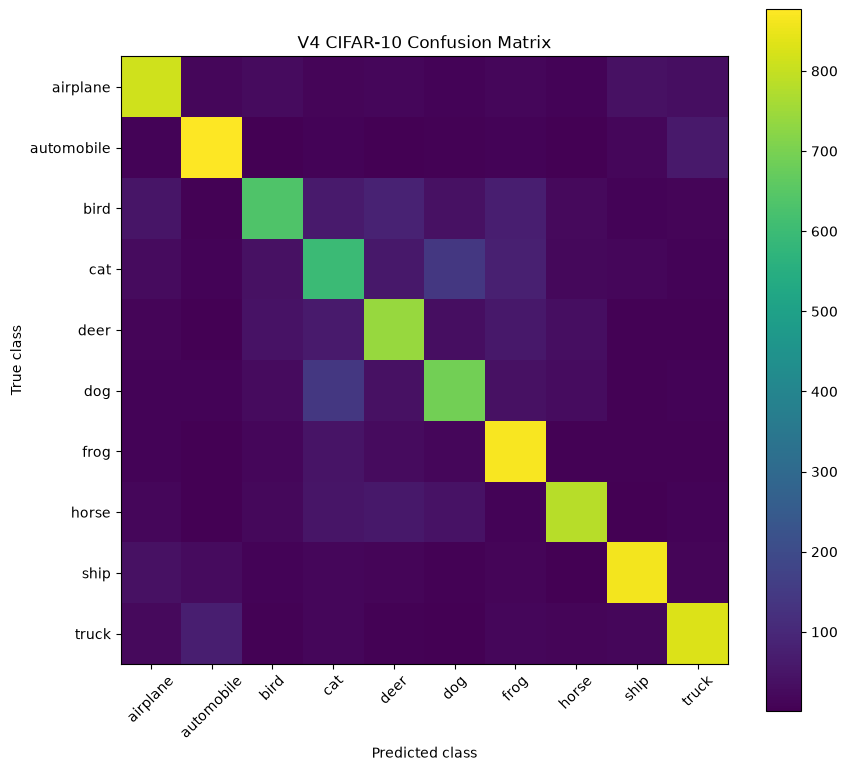

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 8))

plt.imshow(cm)

plt.xticks(
    range(10),
    classes,
    rotation=45
)

plt.yticks(
    range(10),
    classes
)

plt.xlabel("Predicted class")
plt.ylabel("True class")

plt.title(
    "V4 CIFAR-10 Confusion Matrix"
)

plt.colorbar()

plt.tight_layout()

plt.show()

In [29]:
print()
print("====================================")
print("LARGEST CONFUSION PAIRS")
print("====================================")

pairs = []

for i in range(10):
    for j in range(10):

        if i != j:

            pairs.append(
                (
                    cm[i, j],
                    classes[i],
                    classes[j]
                )
            )

pairs.sort(
    reverse=True
)

for count, true_class, predicted_class in pairs[:10]:

    print(
        f"{true_class:12s} → "
        f"{predicted_class:12s}: "
        f"{count} images"
    )


LARGEST CONFUSION PAIRS
cat          → dog         : 144 images
dog          → cat         : 142 images
bird         → deer        : 84 images
cat          → frog        : 77 images
truck        → automobile  : 75 images
bird         → frog        : 75 images
bird         → cat         : 64 images
deer         → cat         : 63 images
automobile   → truck       : 60 images
cat          → deer        : 59 images


In [2]:
# Check current notebook state — no training or file changes

print("Model exists:", "net_v4" in globals())
print("Checkpoint exists in memory:", "checkpoint" in globals())
print("Test loader exists:", "test_loader" in globals())
print("Device exists:", "device" in globals())

Model exists: False
Checkpoint exists in memory: False
Test loader exists: False
Device exists: False


In [15]:
# STEP 4: Recreate the V4 model without training

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

net_v4 = CIFAR10SNN_V4().to(device)

print("Fresh V4 model created.")
print("Device:", device)
print(
    "Total parameters:",
    sum(p.numel() for p in net_v4.parameters())
)

Fresh V4 model created.
Device: cuda
Total parameters: 1962314


In [16]:
# STEP 5: Restore epoch-30 model weights
# This reads the checkpoint; it does not save or overwrite it.

from pathlib import Path

checkpoint_path = Path(
    r"C:\SNN_project\latest_v4_checkpoint.pth"
)

print("Checkpoint file found:", checkpoint_path.exists())

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

net_v4.load_state_dict(
    checkpoint["model_state_dict"]
)

net_v4.eval()

print("\nCheckpoint restored successfully!")
print("Saved epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Training accuracy:", checkpoint["train_accuracy"])
print("Model in evaluation mode:", not net_v4.training)

Checkpoint file found: True

Checkpoint restored successfully!
Saved epoch: 30
Training loss: 0.6886073584291161
Training accuracy: 88.2
Model in evaluation mode: True


In [17]:
# STEP 7: Create the CIFAR-10 test DataLoader
# Uses the existing test_dataset; does not train the model.

from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Preprocessing: ToTensor() only")


NameError: name 'test_dataset' is not defined

In [18]:
# Recreate CIFAR-10 datasets after kernel restart

import torchvision
import torchvision.transforms as transforms

dataset_path = r"C:\SNN_project\cifar-10-python"

train_dataset = torchvision.datasets.CIFAR10(
    root=dataset_path,
    train=True,
    download=False,
    transform=transforms.ToTensor()
)

test_dataset = torchvision.datasets.CIFAR10(
    root=dataset_path,
    train=False,
    download=False,
    transform=transforms.ToTensor()
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


In [19]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test batches:", len(test_loader))

Test batches: 79


In [20]:

# Check whether the variables needed for testing exist

print("test_dataset exists:", "test_dataset" in globals())
print("test_images exists:", "test_images" in globals())
print("test_labels exists:", "test_labels" in globals())
print("utils exists:", "utils" in globals())
print("net_v4 exists:", "net_v4" in globals())


test_dataset exists: True
test_images exists: False
test_labels exists: False
utils exists: True
net_v4 exists: True


In [21]:

# Prepare CIFAR-10 test images and labels

import torch
import numpy as np

test_images = torch.stack([
    test_dataset[i][0]
    for i in range(len(test_dataset))
])

test_labels = torch.tensor([
    test_dataset[i][1]
    for i in range(len(test_dataset))
])

print("Test images shape:", test_images.shape)
print("Test labels shape:", test_labels.shape)
print("Image data type:", test_images.dtype)
print("Label data type:", test_labels.dtype)


Test images shape: torch.Size([10000, 3, 32, 32])
Test labels shape: torch.Size([10000])
Image data type: torch.float32
Label data type: torch.int64


In [22]:

import numpy as np
import torch

def get_v4_predictions(
    net,
    test_images,
    test_labels,
    batch_size=32,
    num_steps=32
):
    net.eval()
    all_predictions = []
    all_labels = []

    num_samples = test_images.shape[0]

    with torch.no_grad():
        for start in range(0, num_samples, batch_size):
            end = min(start + batch_size, num_samples)

            images = test_images[start:end].to(device)
            labels = test_labels[start:end].to(device)

            # Reset neuron states before each batch
            utils.reset(net)

            final_membrane = None

            # Run the 32 simulation time steps
            for step in range(num_steps):
                input_spikes = (
                    torch.rand_like(images) < images
                ).float()

                spk_out, mem_out = net(input_spikes)
                final_membrane = mem_out

            predictions = final_membrane.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            if start == 0 or end == num_samples or start % 1600 == 0:
                print(f"Tested {end}/{num_samples} images")

    return np.array(all_labels), np.array(all_predictions)


true_labels, predicted_labels = get_v4_predictions(
    net_v4,
    test_images,
    test_labels,
    batch_size=32,
    num_steps=num_steps_v4
)

accuracy = 100 * np.mean(true_labels == predicted_labels)

print("\n====================================")
print("V4 TEST RESULT")
print("====================================")
print(f"Test accuracy: {accuracy:.2f}%")


Tested 32/10000 images
Tested 1632/10000 images
Tested 3232/10000 images
Tested 4832/10000 images
Tested 6432/10000 images
Tested 8032/10000 images
Tested 9632/10000 images
Tested 10000/10000 images

V4 TEST RESULT
Test accuracy: 77.12%


In [23]:

import numpy as np

np.savez(
    r"C:\SNN_Project\V4_test_predictions.npz",
    true_labels=true_labels,
    predicted_labels=predicted_labels,
    accuracy=np.array(accuracy)
)

print("Evaluation results saved successfully.")
print(f"Saved test accuracy: {accuracy:.2f}%")
print("File: C:\\SNN_Project\\V4_test_predictions.npz")


Evaluation results saved successfully.
Saved test accuracy: 77.12%
File: C:\SNN_Project\V4_test_predictions.npz


In [24]:

import torch
import numpy as np
from pathlib import Path

# Load the trained epoch-30 checkpoint
checkpoint_path = Path(r"C:\SNN_Project\latest_v4_checkpoint.pth")
output_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["model_state_dict"]

# Export every learned parameter as a NumPy file
weights_dir = output_dir / "weights_float32"
weights_dir.mkdir(exist_ok=True)

manifest = []

for name, tensor in state_dict.items():
    safe_name = name.replace(".", "__")
    array = tensor.detach().cpu().numpy().astype(np.float32)

    np.save(weights_dir / f"{safe_name}.npy", array)

    manifest.append({
        "name": name,
        "file": f"{safe_name}.npy",
        "shape": list(array.shape),
        "dtype": str(array.dtype)
    })

import json

with open(weights_dir / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Parameters exported:", len(manifest))
print("Output folder:", weights_dir)
print("Manifest saved:", weights_dir / "manifest.json")


Checkpoint epoch: 30
Parameters exported: 96
Output folder: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32
Manifest saved: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32\manifest.json


In [25]:

import json
from pathlib import Path

weights_dir = Path(
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32"
)

with open(weights_dir / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

print("=" * 65)
print("V4 SNN — FPGA PARAMETER REPORT")
print("=" * 65)

total_values = 0
total_bytes = 0

for item in manifest:
    array = __import__("numpy").load(weights_dir / item["file"])
    count = int(array.size)
    size = int(array.nbytes)

    total_values += count
    total_bytes += size

    print(
        f'{item["name"]:40s} '
        f'shape={str(item["shape"]):24s} '
        f'values={count:8d}'
    )

print("=" * 65)
print("Parameter tensors:", len(manifest))
print("Total parameter values:", f"{total_values:,}")
print("Float32 parameter storage:", f"{total_bytes / (1024**2):.2f} MiB")


V4 SNN — FPGA PARAMETER REPORT
conv0.weight                             shape=[64, 3, 3, 3]            values=    1728
bn0.weight                               shape=[64]                     values=      64
bn0.bias                                 shape=[64]                     values=      64
bn0.running_mean                         shape=[64]                     values=      64
bn0.running_var                          shape=[64]                     values=      64
bn0.num_batches_tracked                  shape=[]                       values=       1
lif0.threshold                           shape=[]                       values=       1
lif0.graded_spikes_factor                shape=[]                       values=       1
lif0.reset_mechanism_val                 shape=[]                       values=       1
lif0.beta                                shape=[]                       values=       1
res1.conv1.weight                        shape=[64, 64, 3, 3]           values=   36864
r

In [26]:

import json
import numpy as np
from pathlib import Path

weights_dir = Path(
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32"
)

with open(weights_dir / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

print("WEIGHT RANGE ANALYSIS")
print("-" * 75)

for item in manifest:
    name = item["name"]

    # Analyse learned weights only
    if not name.endswith(".weight"):
        continue

    # Skip batch-normalization and LIF parameters
    if name.startswith("bn") or ".bn" in name or name.startswith("lif"):
        continue

    values = np.load(weights_dir / item["file"]).astype(np.float64)

    print(
        f"{name:24s} "
        f"min={values.min(): .6f}  "
        f"max={values.max(): .6f}  "
        f"mean={values.mean(): .6f}  "
        f"std={values.std(): .6f}"
    )


WEIGHT RANGE ANALYSIS
---------------------------------------------------------------------------
conv0.weight             min=-0.576452  max= 0.422820  mean=-0.000555  std= 0.152956
res1.conv1.weight        min=-0.485596  max= 0.636069  mean=-0.003075  std= 0.098539
res1.conv2.weight        min=-0.461314  max= 0.409860  mean=-0.003604  std= 0.098865
conv1.weight             min=-0.438729  max= 0.544478  mean= 0.001101  std= 0.101019
res2.conv1.weight        min=-0.531031  max= 0.504243  mean=-0.003615  std= 0.097973
res2.conv2.weight        min=-0.458718  max= 0.450045  mean=-0.005297  std= 0.098288
conv2.weight             min=-0.441388  max= 0.483049  mean= 0.001092  std= 0.097247
res3.conv1.weight        min=-0.402584  max= 0.393592  mean=-0.002300  std= 0.078177
res3.conv2.weight        min=-0.518489  max= 0.574966  mean= 0.011563  std= 0.074281
fc.weight                min=-0.261981  max= 0.356575  mean=-0.003346  std= 0.057260


In [27]:

import json
import numpy as np
from pathlib import Path

base_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")
weights_dir = base_dir / "weights_float32"
quant_dir = base_dir / "weights_int8_experiment"
quant_dir.mkdir(parents=True, exist_ok=True)

with open(weights_dir / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

quant_manifest = []

for item in manifest:
    name = item["name"]
    array = np.load(weights_dir / item["file"]).astype(np.float32)

    # Keep non-weight tensors unchanged for now.
    # Quantize only convolution and fully connected weights.
    is_layer_weight = (
        name.endswith(".weight")
        and (
            "conv" in name
            or name == "fc.weight"
        )
    )

    if is_layer_weight:
        max_abs = float(np.max(np.abs(array)))
        scale = max_abs / 127.0 if max_abs > 0 else 1.0

        quantized = np.clip(
            np.round(array / scale), -127, 127
        ).astype(np.int8)

        output_file = name.replace(".", "__") + ".npy"
        np.save(quant_dir / output_file, quantized)

        quant_manifest.append({
            "name": name,
            "file": output_file,
            "shape": list(quantized.shape),
            "dtype": "int8",
            "scale": scale,
            "method": "symmetric per-tensor"
        })

with open(quant_dir / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(quant_manifest, f, indent=2)

print("INT8 weight experiment complete.")
print("Quantized weight tensors:", len(quant_manifest))
print("Output folder:", quant_dir)
print("Original float32 exports remain unchanged.")


INT8 weight experiment complete.
Quantized weight tensors: 10
Output folder: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_int8_experiment
Original float32 exports remain unchanged.


In [28]:

import json
import numpy as np
from pathlib import Path

base_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")
float_dir = base_dir / "weights_float32"
int8_dir = base_dir / "weights_int8_experiment"

with open(int8_dir / "manifest.json", "r", encoding="utf-8") as f:
    manifest = json.load(f)

print("INT8 QUANTIZATION ERROR")
print("-" * 78)

overall_squared_error = 0.0
overall_values = 0
overall_max_error = 0.0

for item in manifest:
    name = item["name"]

    original = np.load(
        float_dir / (name.replace(".", "__") + ".npy")
    ).astype(np.float32)

    quantized = np.load(
        int8_dir / item["file"]
    ).astype(np.float32)

    reconstructed = quantized * item["scale"]
    error = original - reconstructed

    mse = float(np.mean(error ** 2))
    rmse = float(np.sqrt(mse))
    max_error = float(np.max(np.abs(error)))

    overall_squared_error += float(np.sum(error ** 2))
    overall_values += error.size
    overall_max_error = max(overall_max_error, max_error)

    print(
        f"{name:24s} "
        f"RMSE={rmse:.6f}  "
        f"Max error={max_error:.6f}"
    )

overall_rmse = np.sqrt(overall_squared_error / overall_values)

print("-" * 78)
print(f"Overall weight RMSE: {overall_rmse:.6f}")
print(f"Overall maximum absolute error: {overall_max_error:.6f}")


INT8 QUANTIZATION ERROR
------------------------------------------------------------------------------
conv0.weight             RMSE=0.001312  Max error=0.002269
res1.conv1.weight        RMSE=0.001445  Max error=0.002504
res1.conv2.weight        RMSE=0.001047  Max error=0.001816
conv1.weight             RMSE=0.001238  Max error=0.002144
res2.conv1.weight        RMSE=0.001207  Max error=0.002091
res2.conv2.weight        RMSE=0.001045  Max error=0.001806
conv2.weight             RMSE=0.001099  Max error=0.001902
res3.conv1.weight        RMSE=0.000915  Max error=0.001585
res3.conv2.weight        RMSE=0.001308  Max error=0.002264
fc.weight                RMSE=0.000808  Max error=0.001404
------------------------------------------------------------------------------
Overall weight RMSE: 0.001128
Overall maximum absolute error: 0.002504


In [29]:

import json
from pathlib import Path

output_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")
output_dir.mkdir(parents=True, exist_ok=True)

architecture = {
    "model_name": "CIFAR10SNN_V4",
    "dataset": "CIFAR-10",
    "input_shape": [3, 32, 32],
    "num_classes": 10,
    "num_time_steps": 32,
    "channels": [64, 128, 256],
    "residual_blocks": 3,
    "pooling": "MaxPool2d(2)",
    "classifier": {
        "type": "Linear",
        "input_features": 4096,
        "output_features": 10
    },
    "residual_block": {
        "conv1": "3x3, padding=1, bias=False",
        "batch_norm1": True,
        "lif1": True,
        "conv2": "3x3, padding=1, bias=False",
        "batch_norm2": True,
        "lif2": True,
        "skip_connection": "out = out + identity"
    },
    "checkpoint_epoch": 30,
    "software_test_accuracy_percent": 77.12,
    "notes": [
        "Accuracy measured using random input spikes.",
        "Verify inference equivalence before reporting final accuracy.",
        "INT8 weights are experimental; full-network quantized accuracy is unverified."
    ]
}

architecture_path = output_dir / "model_architecture.json"

with open(architecture_path, "w", encoding="utf-8") as f:
    json.dump(architecture, f, indent=2)

print("Architecture description saved.")
print("File:", architecture_path)


Architecture description saved.
File: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\model_architecture.json


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nV6 workspace:")
print(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")

print("\nLIF parameter files:")
from pathlib import Path

lif_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32")

for p in sorted(lif_dir.glob("*lif*")):
    print(p.name)

PyTorch version: 2.13.0+cu130
CUDA available: True

V6 workspace:
D:\SNN_Project\SNN_FPGA_V6_CIFAR10

LIF parameter files:
lif0__beta.npy
lif0__graded_spikes_factor.npy
lif0__reset_mechanism_val.npy
lif0__threshold.npy
lif1__beta.npy
lif1__graded_spikes_factor.npy
lif1__reset_mechanism_val.npy
lif1__threshold.npy
lif2__beta.npy
lif2__graded_spikes_factor.npy
lif2__reset_mechanism_val.npy
lif2__threshold.npy
lif_out__beta.npy
lif_out__graded_spikes_factor.npy
lif_out__reset_mechanism_val.npy
lif_out__threshold.npy
res1__lif1__beta.npy
res1__lif1__graded_spikes_factor.npy
res1__lif1__reset_mechanism_val.npy
res1__lif1__threshold.npy
res1__lif2__beta.npy
res1__lif2__graded_spikes_factor.npy
res1__lif2__reset_mechanism_val.npy
res1__lif2__threshold.npy
res2__lif1__beta.npy
res2__lif1__graded_spikes_factor.npy
res2__lif1__reset_mechanism_val.npy
res2__lif1__threshold.npy
res2__lif2__beta.npy
res2__lif2__graded_spikes_factor.npy
res2__lif2__reset_mechanism_val.npy
res2__lif2__threshold.npy
r

In [2]:
import numpy as np
from pathlib import Path

lif_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\weights_float32")

print("LIF neuron parameters")
print("=" * 65)

for name in [
    "lif0", "res1__lif1", "res1__lif2",
    "lif1", "res2__lif1", "res2__lif2",
    "lif2", "res3__lif1", "res3__lif2",
    "lif_out"
]:
    print(f"\n{name}")

    for param in [
        "beta", "threshold",
        "reset_mechanism_val", "graded_spikes_factor"
    ]:
        path = lif_dir / f"{name}__{param}.npy"

        if path.exists():
            values = np.load(path)
            print(f"  {param}: {values}")
        else:
            print(f"  {param}: FILE NOT FOUND")

LIF neuron parameters

lif0
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res1__lif1
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res1__lif2
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

lif1
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res2__lif1
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res2__lif2
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

lif2
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res3__lif1
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1.0

res3__lif2
  beta: 0.8500000238418579
  threshold: 1.0
  reset_mechanism_val: 0.0
  graded_spikes_factor: 1

In [3]:
from pathlib import Path
import json

p = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\model_architecture.json")
architecture = json.loads(p.read_text(encoding="utf-8"))

print(json.dumps(architecture, indent=2))

{
  "model_name": "CIFAR10SNN_V4",
  "dataset": "CIFAR-10",
  "input_shape": [
    3,
    32,
    32
  ],
  "num_classes": 10,
  "num_time_steps": 32,
  "channels": [
    64,
    128,
    256
  ],
  "residual_blocks": 3,
  "pooling": "MaxPool2d(2)",
  "classifier": {
    "type": "Linear",
    "input_features": 4096,
    "output_features": 10
  },
  "residual_block": {
    "conv1": "3x3, padding=1, bias=False",
    "batch_norm1": true,
    "lif1": true,
    "conv2": "3x3, padding=1, bias=False",
    "batch_norm2": true,
    "lif2": true,
    "skip_connection": "out = out + identity"
  },
  "checkpoint_epoch": 30,
  "software_test_accuracy_percent": 77.12,
  "notes": [
    "Accuracy measured using random input spikes.",
    "Verify inference equivalence before reporting final accuracy.",
    "INT8 weights are experimental; full-network quantized accuracy is unverified."
  ]
}


In [4]:
from pathlib import Path
import json

root = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10")

for folder_name in ["weights_float32", "weights_int8_experiment"]:
    folder = root / folder_name
    print(f"\n{folder_name}")

    if not folder.exists():
        print("Folder not found")
        continue

    files = list(folder.glob("*.npy"))
    total_bytes = sum(p.stat().st_size for p in files)

    print("Number of .npy files:", len(files))
    print(f"Total size: {total_bytes / (1024 * 1024):.2f} MiB")

    manifest = folder / "manifest.json"
    print("Manifest exists:", manifest.exists())


weights_float32
Number of .npy files: 96
Total size: 7.51 MiB
Manifest exists: True

weights_int8_experiment
Number of .npy files: 10
Total size: 1.87 MiB
Manifest exists: True


In [5]:
from pathlib import Path

root = Path(r"C:\SNN_project")

for name in [
    "latest_v4_checkpoint.pth",
    "best_v4_model.pth",
    "cifar10_snn_v4_final.pth",
]:
    matches = list(root.rglob(name))
    print(f"\n{name}")
    for p in matches:
        print(f"  Found: {p}")


latest_v4_checkpoint.pth
  Found: C:\SNN_project\latest_v4_checkpoint.pth

best_v4_model.pth
  Found: C:\SNN_project\best_v4_model.pth

cifar10_snn_v4_final.pth
  Found: C:\SNN_project\cifar10_snn_v4_final.pth


In [6]:
import torch
from pathlib import Path

checkpoint_path = Path(r"C:\SNN_project\latest_v4_checkpoint.pth")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"  {key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"  {key}: tensor with shape {tuple(value.shape)}")
        else:
            print(f"  {key}: {value}")

Checkpoint type: <class 'dict'>

Checkpoint keys:
  epoch: 30
  model_state_dict: dictionary with 96 entries
  optimizer_state_dict: dictionary with 2 entries
  scheduler_state_dict: dictionary with 7 entries
  scaler_state_dict: dictionary with 5 entries
  train_loss: 0.6886073584291161
  train_accuracy: 88.2


In [7]:
#exporting parameters
from pathlib import Path
import torch
import numpy as np
import json

checkpoint_path = Path(r"C:\SNN_project\latest_v4_checkpoint.pth")
output_dir = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_export")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["model_state_dict"]

export_manifest = {
    "model_name": "CIFAR10SNN_V4",
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "train_accuracy_percent": float(checkpoint["train_accuracy"]),
    "num_time_steps": 32,
    "input_shape": [3, 32, 32],
    "num_classes": 10,
    "tensors": {}
}

for name, tensor in state.items():
    array = tensor.detach().cpu().numpy()
    filename = name.replace(".", "__") + ".npy"
    np.save(output_dir / filename, array)

    export_manifest["tensors"][name] = {
        "file": filename,
        "shape": list(array.shape),
        "dtype": str(array.dtype)
    }

(output_dir / "manifest.json").write_text(
    json.dumps(export_manifest, indent=2),
    encoding="utf-8"
)

print("Export complete:", output_dir)
print("Exported tensors:", len(state))
print("Manifest:", output_dir / "manifest.json")

Export complete: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_export
Exported tensors: 96
Manifest: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_export\manifest.json


In [8]:
import torch

checkpoint = torch.load(
    r"C:\SNN_project\latest_v4_checkpoint.pth",
    map_location="cpu",
    weights_only=False
)

for name, tensor in checkpoint["model_state_dict"].items():
    print(f"{name:40s} {tuple(tensor.shape)}")

conv0.weight                             (64, 3, 3, 3)
bn0.weight                               (64,)
bn0.bias                                 (64,)
bn0.running_mean                         (64,)
bn0.running_var                          (64,)
bn0.num_batches_tracked                  ()
lif0.threshold                           ()
lif0.graded_spikes_factor                ()
lif0.reset_mechanism_val                 ()
lif0.beta                                ()
res1.conv1.weight                        (64, 64, 3, 3)
res1.bn1.weight                          (64,)
res1.bn1.bias                            (64,)
res1.bn1.running_mean                    (64,)
res1.bn1.running_var                     (64,)
res1.bn1.num_batches_tracked             ()
res1.lif1.threshold                      ()
res1.lif1.graded_spikes_factor           ()
res1.lif1.reset_mechanism_val            ()
res1.lif1.beta                           ()
res1.conv2.weight                        (64, 64, 3, 3)
res1.bn2.weight  

In [9]:
import json
from pathlib import Path

config = {
    "model": "CIFAR10SNN_V4",
    "input": {"channels": 3, "height": 32, "width": 32},
    "timesteps": 32,
    "classes": 10,
    "layers": [
        {"name": "conv0", "type": "conv2d", "in_channels": 3, "out_channels": 64, "kernel": 3, "padding": 1, "batch_norm": "bn0", "lif": "lif0", "pool": 2},
        {"name": "res1", "type": "residual", "channels": 64, "blocks": 2},
        {"name": "conv1", "type": "conv2d", "in_channels": 64, "out_channels": 128, "kernel": 3, "padding": 1, "batch_norm": "bn1", "lif": "lif1", "pool": 2},
        {"name": "res2", "type": "residual", "channels": 128, "blocks": 2},
        {"name": "conv2", "type": "conv2d", "in_channels": 128, "out_channels": 256, "kernel": 3, "padding": 1, "batch_norm": "bn2", "lif": "lif2", "pool": 2},
        {"name": "res3", "type": "residual", "channels": 256, "blocks": 2},
        {"name": "fc", "type": "linear", "in_features": 4096, "out_features": 10, "bias": True, "lif": "lif_out"}
    ],
    "notes": [
        "Configuration describes the intended architecture, not a verified FPGA implementation.",
        "Residual blocks contain two convolution-BatchNorm-LIF stages and an identity addition.",
        "Fixed-point arithmetic and full-network accuracy must be validated."
    ]
}

path = Path(r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_export\layer_config.json")
path.write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Saved:", path)
print(json.dumps(config, indent=2))

Saved: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_export\layer_config.json
{
  "model": "CIFAR10SNN_V4",
  "input": {
    "channels": 3,
    "height": 32,
    "width": 32
  },
  "timesteps": 32,
  "classes": 10,
  "layers": [
    {
      "name": "conv0",
      "type": "conv2d",
      "in_channels": 3,
      "out_channels": 64,
      "kernel": 3,
      "padding": 1,
      "batch_norm": "bn0",
      "lif": "lif0",
      "pool": 2
    },
    {
      "name": "res1",
      "type": "residual",
      "channels": 64,
      "blocks": 2
    },
    {
      "name": "conv1",
      "type": "conv2d",
      "in_channels": 64,
      "out_channels": 128,
      "kernel": 3,
      "padding": 1,
      "batch_norm": "bn1",
      "lif": "lif1",
      "pool": 2
    },
    {
      "name": "res2",
      "type": "residual",
      "channels": 128,
      "blocks": 2
    },
    {
      "name": "conv2",
      "type": "conv2d",
      "in_channels": 128,
      "out_channels": 256,
      "kernel": 3,
      "padding": 

In [1]:
import torch

print("PyTorch:", torch.__version__)

# Find the model variable already loaded in your notebook.
for candidate_name in ["net", "model"]:
    candidate = globals().get(candidate_name)
    if isinstance(candidate, torch.nn.Module):
        net = candidate
        print("Model variable found:", candidate_name)
        break
else:
    net = None
    print("No loaded model found. We will load the saved checkpoint.")

if net is not None:
    for name, module in net.named_modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            print(f"{name}: eps={module.eps}")

PyTorch: 2.13.0+cu130
No loaded model found. We will load the saved checkpoint.


In [12]:
import torch

checkpoint_path = r"C:\SNN_project\cifar10_snn_v4_final.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:30])

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['conv0.weight', 'bn0.weight', 'bn0.bias', 'bn0.running_mean', 'bn0.running_var', 'bn0.num_batches_tracked', 'lif0.threshold', 'lif0.graded_spikes_factor', 'lif0.reset_mechanism_val', 'lif0.beta', 'res1.conv1.weight', 'res1.bn1.weight', 'res1.bn1.bias', 'res1.bn1.running_mean', 'res1.bn1.running_var', 'res1.bn1.num_batches_tracked', 'res1.lif1.threshold', 'res1.lif1.graded_spikes_factor', 'res1.lif1.reset_mechanism_val', 'res1.lif1.beta', 'res1.conv2.weight', 'res1.bn2.weight', 'res1.bn2.bias', 'res1.bn2.running_mean', 'res1.bn2.running_var', 'res1.bn2.num_batches_tracked', 'res1.lif2.threshold', 'res1.lif2.graded_spikes_factor', 'res1.lif2.reset_mechanism_val', 'res1.lif2.beta']


In [13]:
import torch

device = torch.device("cpu")

net = CIFAR10SNN_V4().to(device)

checkpoint = torch.load(
    r"C:\SNN_project\cifar10_snn_v4_final.pth",
    map_location=device,
    weights_only=True
)

net.load_state_dict(checkpoint)
net.eval()

print("Model loaded successfully!")
print("Total parameters:", sum(p.numel() for p in net.parameters()))

for name, module in net.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        print(f"{name}: eps={module.eps}")

Model loaded successfully!
Total parameters: 1962314
bn0: eps=1e-05
res1.bn1: eps=1e-05
res1.bn2: eps=1e-05
bn1: eps=1e-05
res2.bn1: eps=1e-05
res2.bn2: eps=1e-05
bn2: eps=1e-05
res3.bn1: eps=1e-05
res3.bn2: eps=1e-05


In [14]:
import torch

assert net is not None
net.eval()

# Check all model parameters
bad_parameters = []
for name, param in net.named_parameters():
    if not torch.isfinite(param).all():
        bad_parameters.append(name)

# Check BatchNorm running statistics
bad_bn_stats = []
for name, module in net.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        if (
            not torch.isfinite(module.running_mean).all()
            or not torch.isfinite(module.running_var).all()
        ):
            bad_bn_stats.append(name)

print("Non-finite parameters:", bad_parameters)
print("Non-finite BatchNorm statistics:", bad_bn_stats)
print("Model is in evaluation mode:", not net.training)

assert not bad_parameters, "Some model parameters are invalid."
assert not bad_bn_stats, "Some BatchNorm statistics are invalid."

print("\nModel parameter validation passed.")

Non-finite parameters: []
Non-finite BatchNorm statistics: []
Model is in evaluation mode: True

Model parameter validation passed.


In [15]:
import os
import json
import numpy as np
import torch

# Output directory for fixed-point BatchNorm coefficients
OUTPUT_DIR = r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_params\bn_fixed"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Q format: signed integer with 16 fractional bits
FRAC_BITS = 16
SCALE = 1 << FRAC_BITS

manifest = {
    "format": "signed_fixed_point",
    "fractional_bits": FRAC_BITS,
    "scale": SCALE,
    "batchnorm_eps": 1e-5,
    "layers": {}
}

for name, module in net.named_modules():
    if not isinstance(module, torch.nn.BatchNorm2d):
        continue

    gamma = module.weight.detach().cpu().numpy().astype(np.float64)
    beta = module.bias.detach().cpu().numpy().astype(np.float64)
    mean = module.running_mean.detach().cpu().numpy().astype(np.float64)
    var = module.running_var.detach().cpu().numpy().astype(np.float64)

    a = gamma / np.sqrt(var + module.eps)
    b = beta - a * mean

    # Quantize to signed 32-bit integers with 16 fractional bits.
    a_fixed = np.clip(
        np.rint(a * SCALE), -(2**31), 2**31 - 1
    ).astype(np.int32)

    b_fixed = np.clip(
        np.rint(b * SCALE), -(2**31), 2**31 - 1
    ).astype(np.int32)

    safe_name = name.replace(".", "__")

    np.save(os.path.join(OUTPUT_DIR, f"{safe_name}_a_fixed.npy"), a_fixed)
    np.save(os.path.join(OUTPUT_DIR, f"{safe_name}_b_fixed.npy"), b_fixed)

    # Measure coefficient quantization error after converting back to float.
    a_reconstructed = a_fixed.astype(np.float64) / SCALE
    b_reconstructed = b_fixed.astype(np.float64) / SCALE

    manifest["layers"][name] = {
        "channels": int(len(a)),
        "eps": float(module.eps),
        "max_abs_scale_error": float(np.max(np.abs(a - a_reconstructed))),
        "max_abs_offset_error": float(np.max(np.abs(b - b_reconstructed)))
    }

with open(os.path.join(OUTPUT_DIR, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)

print("Fixed-point BatchNorm export completed.")
print("Output directory:", OUTPUT_DIR)
print("Fractional bits:", FRAC_BITS)
print("Layers exported:", len(manifest["layers"]))

for name, info in manifest["layers"].items():
    print(
        f"{name}: channels={info['channels']}, "
        f"max scale error={info['max_abs_scale_error']:.8g}, "
        f"max offset error={info['max_abs_offset_error']:.8g}"
    )

Fixed-point BatchNorm export completed.
Output directory: D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_params\bn_fixed
Fractional bits: 16
Layers exported: 9
bn0: channels=64, max scale error=7.5658135e-06, max offset error=7.5499463e-06
res1.bn1: channels=64, max scale error=7.5556902e-06, max offset error=7.6180272e-06
res1.bn2: channels=64, max scale error=7.6239578e-06, max offset error=7.5561369e-06
bn1: channels=128, max scale error=7.6251248e-06, max offset error=7.606045e-06
res2.bn1: channels=128, max scale error=7.5331735e-06, max offset error=7.6269622e-06
res2.bn2: channels=128, max scale error=7.6253155e-06, max offset error=7.5778493e-06
bn2: channels=256, max scale error=7.579683e-06, max offset error=7.5699561e-06
res3.bn1: channels=256, max scale error=7.6252421e-06, max offset error=7.6153142e-06
res3.bn2: channels=256, max scale error=7.6231675e-06, max offset error=7.5705626e-06


In [7]:
# Find existing dataset and DataLoader variables
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["loader", "dataset", "cifar", "test_data"]):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

CIFAR10SNN_V4: type


In [8]:
# Check common CIFAR-10 dataset and DataLoader variables
names_to_check = [
    "test_loader", "testloader", "test_dl",
    "testset", "test_dataset", "test_data",
    "train_loader", "trainloader", "transform_test",
    "test_transform", "cifar10_test"
]

for name in names_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
    else:
        print(f"{name}: not defined")

test_loader: not defined
testloader: not defined
test_dl: not defined
testset: not defined
test_dataset: not defined
test_data: not defined
train_loader: not defined
trainloader: not defined
transform_test: not defined
test_transform: not defined
cifar10_test: not defined


In [9]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Match the model's original input preprocessing
test_transform = transforms.ToTensor()

test_dataset = datasets.CIFAR10(
    root=r"C:\SNN_project\data",
    train=False,
    download=True,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(test_loader))

print("Test dataset loaded successfully.")
print("Number of test images:", len(test_dataset))
print("Image shape:", tuple(images.shape))
print("Pixel range:", images.min().item(), "to", images.max().item())
print("First image label:", labels.item())

100.0%


Test dataset loaded successfully.
Number of test images: 10000
Image shape: (1, 3, 32, 32)
Pixel range: 0.05098039284348488 to 1.0
First image label: 3


In [10]:
import os
import numpy as np
import torch

OUTPUT_DIR = (
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10"
    r"\hardware_params\bn_fixed"
)

FRAC_BITS = 16
SCALE = 1 << FRAC_BITS
device = next(net.parameters()).device

captured_inputs = {}
hooks = []

def make_hook(name):
    def hook(module, inputs):
        captured_inputs[name] = inputs[0].detach().clone()
    return hook

# Capture inputs to all BatchNorm2d layers
for name, module in net.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        hooks.append(
            module.register_forward_pre_hook(make_hook(name))
        )

images, labels = next(iter(test_loader))
image = images.to(device)

net.eval()

try:
    with torch.no_grad():
        _ = net(image)
finally:
    for hook in hooks:
        hook.remove()

print("Real-activation BatchNorm comparison\n")

for name, module in net.named_modules():
    if not isinstance(module, torch.nn.BatchNorm2d):
        continue

    x = captured_inputs[name].to(device)
    safe_name = name.replace(".", "__")

    a_fixed = torch.from_numpy(
        np.load(
            os.path.join(
                OUTPUT_DIR, f"{safe_name}_a_fixed.npy"
            )
        ).astype(np.float32) / SCALE
    ).to(device)

    b_fixed = torch.from_numpy(
        np.load(
            os.path.join(
                OUTPUT_DIR, f"{safe_name}_b_fixed.npy"
            )
        ).astype(np.float32) / SCALE
    ).to(device)

    shape = [1, -1] + [1] * (x.ndim - 2)
    a_fixed = a_fixed.reshape(shape)
    b_fixed = b_fixed.reshape(shape)

    with torch.no_grad():
        y_reference = module(x)
        y_reconstructed = x * a_fixed + b_fixed

    error = (y_reference - y_reconstructed).abs()

    print(
        f"{name:12s} | "
        f"max error: {error.max().item():.8g} | "
        f"mean error: {error.mean().item():.8g}"
    )

print("\nReal-activation comparison completed.")

NameError: name 'net' is not defined

In [11]:
import torch
import os

CHECKPOINT_PATH = r"C:\SNN_project\cifar10_snn_v4_final.pth"

# Recreate the model architecture
device = torch.device("cpu")
net = CIFAR10SNN_V4().to(device)

# Load the saved trained weights
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

net.load_state_dict(checkpoint)
net.eval()

print("Model restored successfully!")
print("Device:", next(net.parameters()).device)
print("Evaluation mode:", not net.training)
print("Parameters:", sum(p.numel() for p in net.parameters()))

Model restored successfully!
Device: cpu
Evaluation mode: True
Parameters: 1962314


In [12]:
import os
import numpy as np
import torch

OUTPUT_DIR = (
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10"
    r"\hardware_params\bn_fixed"
)

FRAC_BITS = 16
SCALE = 1 << FRAC_BITS
device = next(net.parameters()).device

captured_inputs = {}
hooks = []

def make_hook(name):
    def hook(module, inputs):
        captured_inputs[name] = inputs[0].detach().clone()
    return hook

for name, module in net.named_modules():
    if isinstance(module, torch.nn.BatchNorm2d):
        hooks.append(module.register_forward_pre_hook(make_hook(name)))

images, labels = next(iter(test_loader))
image = images.to(device)

net.eval()
try:
    with torch.no_grad():
        _ = net(image)
finally:
    for hook in hooks:
        hook.remove()

print("Real-activation BatchNorm comparison\n")

for name, module in net.named_modules():
    if not isinstance(module, torch.nn.BatchNorm2d):
        continue

    x = captured_inputs[name].to(device)
    safe_name = name.replace(".", "__")

    a_fixed = torch.from_numpy(
        np.load(os.path.join(
            OUTPUT_DIR, f"{safe_name}_a_fixed.npy"
        )).astype(np.float32) / SCALE
    ).to(device)

    b_fixed = torch.from_numpy(
        np.load(os.path.join(
            OUTPUT_DIR, f"{safe_name}_b_fixed.npy"
        )).astype(np.float32) / SCALE
    ).to(device)

    shape = [1, -1] + [1] * (x.ndim - 2)
    a_fixed = a_fixed.reshape(shape)
    b_fixed = b_fixed.reshape(shape)

    with torch.no_grad():
        y_reference = module(x)
        y_reconstructed = x * a_fixed + b_fixed

    error = (y_reference - y_reconstructed).abs()
    print(
        f"{name:12s} | max error: {error.max().item():.8g} | "
        f"mean error: {error.mean().item():.8g}"
    )

print("\nReal-activation comparison completed.")

Real-activation BatchNorm comparison

bn0          | max error: 1.5258789e-05 | mean error: 3.7857289e-06
res1.bn1     | max error: 3.6716461e-05 | mean error: 4.3629084e-06
res1.bn2     | max error: 3.695488e-05 | mean error: 6.6494649e-06
bn1          | max error: 6.1750412e-05 | mean error: 6.1397404e-06
res2.bn1     | max error: 5.209446e-05 | mean error: 6.9606031e-06
res2.bn2     | max error: 5.6147575e-05 | mean error: 9.9060053e-06
bn2          | max error: 8.4280968e-05 | mean error: 9.4732277e-06
res3.bn1     | max error: 8.7171793e-06 | mean error: 3.7687946e-06
res3.bn2     | max error: 9.1791153e-06 | mean error: 3.7517839e-06

Real-activation comparison completed.


In [13]:
import torch

# Confirm these settings match your original training/inference code.
NUM_STEPS = 32

net.eval()
device = next(net.parameters()).device

images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)

# Reproducible random input spikes for this run
torch.manual_seed(42)

# Reset neuron states if the original snntorch utility is available.
try:
    from snntorch import utils
    utils.reset(net)
except ImportError:
    print("snntorch utility unavailable; use your original reset method.")

spike_counts = None
final_membrane = None

with torch.no_grad():
    for step in range(NUM_STEPS):
        input_spikes = (torch.rand_like(images) < images).float()
        spk_out, mem_out = net(input_spikes)

        if spike_counts is None:
            spike_counts = spk_out.clone()
        else:
            spike_counts += spk_out

        final_membrane = mem_out

prediction = final_membrane.argmax(dim=1)

print("True label:", labels.item())
print("Predicted class:", prediction.item())
print("Correct:", prediction.item() == labels.item())
print("Timesteps:", NUM_STEPS)
print("Spike count per output class:", spike_counts.cpu().numpy())
print("Final membrane potentials:", final_membrane.cpu().numpy())

True label: 3
Predicted class: 3
Correct: True
Timesteps: 32
Spike count per output class: [[0. 0. 0. 8. 0. 0. 2. 0. 0. 0.]]
Final membrane potentials: [[-6.0023365 -3.3097534 -8.430291   1.6932988 -6.255163  -2.5027003
  -5.209266  -6.0028973 -1.2106643 -6.0193167]]


In [14]:
import torch
from snntorch import utils

net.eval()
device = next(net.parameters()).device

NUM_STEPS = 32
NUM_IMAGES = 100
BATCH_SIZE = 10

correct = 0
total = 0

torch.manual_seed(42)

for images, labels in torch.utils.data.DataLoader(
    torch.utils.data.Subset(test_dataset, range(NUM_IMAGES)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
):
    images = images.to(device)
    labels = labels.to(device)

    utils.reset(net)
    final_membrane = None

    with torch.no_grad():
        for step in range(NUM_STEPS):
            input_spikes = (torch.rand_like(images) < images).float()
            _, final_membrane = net(input_spikes)

    predictions = final_membrane.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.numel()

accuracy = 100.0 * correct / total

print(f"Images evaluated: {total}")
print(f"Correct predictions: {correct}")
print(f"Software baseline accuracy: {accuracy:.2f}%")

Images evaluated: 100
Correct predictions: 81
Software baseline accuracy: 81.00%


In [15]:
import torch
import numpy as np
from torch.utils.data import DataLoader, Subset
from snntorch import utils

net.eval()
device = next(net.parameters()).device

NUM_STEPS = 32
NUM_IMAGES = 100
BATCH_SIZE = 10

torch.manual_seed(42)

loader = DataLoader(
    Subset(test_dataset, range(NUM_IMAGES)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

all_labels = []
all_predictions = []
all_membranes = []

for images, labels in loader:
    images = images.to(device)
    labels = labels.to(device)

    utils.reset(net)
    final_membrane = None

    with torch.no_grad():
        for _ in range(NUM_STEPS):
            input_spikes = (
                torch.rand_like(images) < images
            ).float()
            _, final_membrane = net(input_spikes)

    predictions = final_membrane.argmax(dim=1)

    all_labels.extend(labels.cpu().numpy())
    all_predictions.extend(predictions.cpu().numpy())
    all_membranes.extend(final_membrane.cpu().numpy())

all_labels = np.asarray(all_labels)
all_predictions = np.asarray(all_predictions)
all_membranes = np.asarray(all_membranes)

accuracy = 100 * np.mean(all_predictions == all_labels)

np.savez(
    r"C:\SNN_project\fp32_reference_100.npz",
    labels=all_labels,
    predictions=all_predictions,
    final_membranes=all_membranes,
    seed=42,
    timesteps=NUM_STEPS
)

print("Reference saved: C:\\SNN_project\\fp32_reference_100.npz")
print("Images:", len(all_labels))
print("Accuracy:", f"{accuracy:.2f}%")

Reference saved: C:\SNN_project\fp32_reference_100.npz
Images: 100
Accuracy: 81.00%


In [16]:
import os
import json
import numpy as np

BASE_DIR = (
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10"
    r"\weights_int8_experiment"
)

print("INT8 export directory exists:", os.path.isdir(BASE_DIR))

if not os.path.isdir(BASE_DIR):
    print("ERROR: Check the directory path.")
else:
    for filename in sorted(os.listdir(BASE_DIR)):
        path = os.path.join(BASE_DIR, filename)

        if os.path.isfile(path):
            print(f"\nFILE: {filename}")
            print(f"Size: {os.path.getsize(path):,} bytes")

            if filename.endswith(".json"):
                with open(path, "r") as f:
                    manifest = json.load(f)
                print(json.dumps(manifest, indent=2))

            elif filename.endswith(".npy"):
                arr = np.load(path, mmap_mode="r")
                print("Shape:", arr.shape)
                print("Data type:", arr.dtype)

                if np.issubdtype(arr.dtype, np.integer):
                    print("Min:", int(arr.min()))
                    print("Max:", int(arr.max()))

INT8 export directory exists: True

FILE: conv0__weight.npy
Size: 1,856 bytes
Shape: (64, 3, 3, 3)
Data type: int8
Min: -127
Max: 93

FILE: conv1__weight.npy
Size: 73,856 bytes
Shape: (128, 64, 3, 3)
Data type: int8
Min: -102
Max: 127

FILE: conv2__weight.npy
Size: 295,040 bytes
Shape: (256, 128, 3, 3)
Data type: int8
Min: -116
Max: 127

FILE: fc__weight.npy
Size: 41,088 bytes
Shape: (10, 4096)
Data type: int8
Min: -93
Max: 127

FILE: manifest.json
Size: 2,406 bytes
[
  {
    "name": "conv0.weight",
    "file": "conv0__weight.npy",
    "shape": [
      64,
      3,
      3,
      3
    ],
    "dtype": "int8",
    "scale": 0.004538990381195789,
    "method": "symmetric per-tensor"
  },
  {
    "name": "res1.conv1.weight",
    "file": "res1__conv1__weight.npy",
    "shape": [
      64,
      64,
      3,
      3
    ],
    "dtype": "int8",
    "scale": 0.005008420606297771,
    "method": "symmetric per-tensor"
  },
  {
    "name": "res1.conv2.weight",
    "file": "res1__conv2__weight.npy

In [17]:
import os
import json
import numpy as np
import torch

BASE_DIR = (
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10"
    r"\weights_int8_experiment"
)

with open(os.path.join(BASE_DIR, "manifest.json"), "r") as f:
    manifest = json.load(f)

state = net.state_dict()
results = []

print("INT8 weight reconstruction validation\n")

for item in manifest:
    name = item["name"]
    filename = item["file"]
    scale = float(item["scale"])

    qweight = np.load(
        os.path.join(BASE_DIR, filename)
    )

    original = state[name].detach().cpu().numpy()

    # Reconstruct floating-point weights from INT8 and scale.
    reconstructed = qweight.astype(np.float32) * scale

    assert qweight.dtype == np.int8, (
        f"{name}: expected int8, got {qweight.dtype}"
    )
    assert qweight.shape == original.shape, (
        f"{name}: shape mismatch: {qweight.shape} vs {original.shape}"
    )

    error = original - reconstructed

    max_error = float(np.max(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error ** 2)))
    mean_error = float(np.mean(np.abs(error)))

    results.append({
        "name": name,
        "max_abs_error": max_error,
        "rmse": rmse,
        "mean_abs_error": mean_error
    })

    print(
        f"{name:20s} | "
        f"max={max_error:.8g} | "
        f"RMSE={rmse:.8g} | "
        f"mean={mean_error:.8g}"
    )

print("\nValidated tensors:", len(results))
print("All shapes and data types passed.")

INT8 weight reconstruction validation

conv0.weight         | max=0.0022690967 | RMSE=0.001311906 | mean=0.0011416421
res1.conv1.weight    | max=0.0025042146 | RMSE=0.0014452981 | mean=0.001250617
res1.conv2.weight    | max=0.001816133 | RMSE=0.0010469524 | mean=0.00090684299
conv1.weight         | max=0.0021435916 | RMSE=0.0012379502 | mean=0.0010725432
res2.conv1.weight    | max=0.0020906366 | RMSE=0.0012073086 | mean=0.0010450961
res2.conv2.weight    | max=0.0018059686 | RMSE=0.0010446243 | mean=0.00090469752
conv2.weight         | max=0.0019017607 | RMSE=0.0010985709 | mean=0.00095143419
res3.conv1.weight    | max=0.001584962 | RMSE=0.00091543805 | mean=0.00079273339
res3.conv2.weight    | max=0.0022636428 | RMSE=0.0013077259 | mean=0.0011327541
fc.weight            | max=0.0014038382 | RMSE=0.00080837519 | mean=0.00069940893

Validated tensors: 10
All shapes and data types passed.


In [19]:
import os
import json
import copy
import numpy as np
import torch

BASE_DIR = (
    r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10"
    r"\weights_int8_experiment"
)

# Load the existing export manifest.
with open(os.path.join(BASE_DIR, "manifest.json"), "r") as f:
    manifest = json.load(f)

# Preserve the original FP32 model.
net_int8w = copy.deepcopy(net)
net_int8w.eval()

# Replace weights only in the copied model.
with torch.no_grad():
    for item in manifest:
        name = item["name"]
        filename = item["file"]
        scale = float(item["scale"])

        qweight = np.load(
            os.path.join(BASE_DIR, filename)
        )

        reconstructed = (
            torch.from_numpy(qweight.copy()).to(torch.float32) * scale
        )

        parameter = dict(net_int8w.named_parameters())[name]

        assert parameter.shape == reconstructed.shape, (
            f"Shape mismatch for {name}"
        )

        parameter.copy_(reconstructed.to(parameter.device))

# Verify that the original model was not modified.
original_state = net.state_dict()
quantized_state = net_int8w.state_dict()

max_difference = 0.0
for name, item in manifest and original_state.items():
    if name in original_state:
        if original_state[name].is_floating_point():
            difference = (
                original_state[name] - quantized_state[name]
            ).abs().max().item()
            max_difference = max(max_difference, difference)

print("Quantized-weight copy created.")
print("Original model remains separate:", net is not net_int8w)
print("Maximum parameter difference across state:", max_difference)
print("INT8 weight layers replaced:", len(manifest))

Quantized-weight copy created.
Original model remains separate: True
Maximum parameter difference across state: 0.002504214644432068
INT8 weight layers replaced: 10


In [20]:
max_weight_difference = 0.0

for item in manifest:
    name = item["name"]
    diff = (
        original_state[name] - quantized_state[name]
    ).abs().max().item()
    max_weight_difference = max(max_weight_difference, diff)

print("Quantized-weight copy created.")
print("Original model remains separate:", net is not net_int8w)
print("Maximum change among exported weight tensors:",
      max_weight_difference)
print("INT8 weight layers replaced:", len(manifest))

Quantized-weight copy created.
Original model remains separate: True
Maximum change among exported weight tensors: 0.002504214644432068
INT8 weight layers replaced: 10


In [21]:
import torch
import numpy as np
from torch.utils.data import DataLoader, Subset
from snntorch import utils

NUM_IMAGES = 100
NUM_STEPS = 32
BATCH_SIZE = 10
SEED = 42

device = next(net.parameters()).device

loader = DataLoader(
    Subset(test_dataset, range(NUM_IMAGES)),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

net.eval()
net_int8w.eval()

fp32_predictions = []
int8w_predictions = []
labels_all = []

# Save and restore the RNG state so both models receive
# exactly the same stochastic input spike sequences.
rng_state_before = torch.random.get_rng_state()

try:
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Generate one shared sequence of input spikes.
        torch.manual_seed(SEED)
        spike_sequence = [
            (torch.rand_like(images) < images).float()
            for _ in range(NUM_STEPS)
        ]

        # Original FP32 model
        utils.reset(net)
        with torch.no_grad():
            for spikes in spike_sequence:
                _, fp32_mem = net(spikes)
        fp32_pred = fp32_mem.argmax(dim=1)

        # INT8-weight reconstruction model
        utils.reset(net_int8w)
        with torch.no_grad():
            for spikes in spike_sequence:
                _, int8w_mem = net_int8w(spikes)
        int8w_pred = int8w_mem.argmax(dim=1)

        fp32_predictions.extend(fp32_pred.cpu().numpy())
        int8w_predictions.extend(int8w_pred.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

finally:
    torch.random.set_rng_state(rng_state_before)

fp32_predictions = np.asarray(fp32_predictions)
int8w_predictions = np.asarray(int8w_predictions)
labels_all = np.asarray(labels_all)

fp32_acc = 100 * np.mean(fp32_predictions == labels_all)
int8w_acc = 100 * np.mean(int8w_predictions == labels_all)
agreement = 100 * np.mean(fp32_predictions == int8w_predictions)

print(f"FP32 accuracy:              {fp32_acc:.2f}%")
print(f"INT8-weight model accuracy: {int8w_acc:.2f}%")
print(f"Prediction agreement:       {agreement:.2f}%")
print(
    "Changed predictions:",
    int(np.sum(fp32_predictions != int8w_predictions)),
    "out of",
    len(labels_all)
)

FP32 accuracy:              77.00%
INT8-weight model accuracy: 83.00%
Prediction agreement:       80.00%
Changed predictions: 20 out of 100


In [22]:

import torch
import time

# Configuration
TIMESTEPS = 32
SEED = 42
device = next(net.parameters()).device

# Verify that both models and the test dataset are available
assert "net_int8w" in globals(), "INT8-weight model not found. Create net_int8w first."
assert len(test_loader.dataset) == 10000, "Expected the full 10,000-image CIFAR-10 test set."

net.eval()
net_int8w.eval()

# Keep both models on the same device
net_int8w = net_int8w.to(device)

fp32_correct = 0
int8_correct = 0
agreement = 0
changed = 0
total = 0

torch.manual_seed(SEED)
if torch.cuda.is_available() and device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

start_time = time.time()

with torch.inference_mode():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images = images.to(device)
        labels = labels.to(device)
        batch_size = images.size(0)

        # Generate ONE shared set of input spikes for both models.
        # This makes the comparison fair.
        shared_spikes = [
            (torch.rand_like(images) < images).float()
            for _ in range(TIMESTEPS)
        ]

        # ----- FP32 model -----
        utils.reset(net)
        fp32_final_mem = None

        for spikes in shared_spikes:
            _, mem = net(spikes)
            fp32_final_mem = mem

        fp32_preds = fp32_final_mem.argmax(dim=1)

        # ----- INT8-weight model -----
        utils.reset(net_int8w)
        int8_final_mem = None

        for spikes in shared_spikes:
            _, mem = net_int8w(spikes)
            int8_final_mem = mem

        int8_preds = int8_final_mem.argmax(dim=1)

        # Accumulate results
        fp32_correct += (fp32_preds == labels).sum().item()
        int8_correct += (int8_preds == labels).sum().item()
        agreement += (fp32_preds == int8_preds).sum().item()
        changed += (fp32_preds != int8_preds).sum().item()
        total += batch_size

        if (batch_idx + 1) % 50 == 0 or total == len(test_loader.dataset):
            elapsed = time.time() - start_time
            print(
                f"Processed {total:5d}/10000 images | "
                f"FP32: {100*fp32_correct/total:.2f}% | "
                f"INT8-weight: {100*int8_correct/total:.2f}% | "
                f"Elapsed: {elapsed/60:.1f} min"
            )

print("\n" + "=" * 48)
print("FULL CIFAR-10 TEST SET RESULTS")
print("=" * 48)
print(f"Images evaluated:          {total}")
print(f"FP32 accuracy:              {100*fp32_correct/total:.2f}%")
print(f"INT8-weight model accuracy: {100*int8_correct/total:.2f}%")
print(f"Prediction agreement:       {100*agreement/total:.2f}%")
print(f"Changed predictions:        {changed} out of {total}")
print(f"Accuracy difference:        {100*(int8_correct-fp32_correct)/total:+.2f} percentage points")
print(f"Total time:                 {(time.time()-start_time)/60:.1f} minutes")


Processed    50/10000 images | FP32: 78.00% | INT8-weight: 80.00% | Elapsed: 0.4 min
Processed   100/10000 images | FP32: 77.00% | INT8-weight: 79.00% | Elapsed: 0.8 min
Processed   150/10000 images | FP32: 80.00% | INT8-weight: 80.67% | Elapsed: 1.1 min
Processed   200/10000 images | FP32: 80.50% | INT8-weight: 81.00% | Elapsed: 1.5 min
Processed   250/10000 images | FP32: 78.80% | INT8-weight: 80.40% | Elapsed: 1.8 min
Processed   300/10000 images | FP32: 77.67% | INT8-weight: 79.67% | Elapsed: 2.1 min
Processed   350/10000 images | FP32: 77.71% | INT8-weight: 79.43% | Elapsed: 2.5 min
Processed   400/10000 images | FP32: 77.50% | INT8-weight: 79.25% | Elapsed: 2.8 min
Processed   450/10000 images | FP32: 77.11% | INT8-weight: 79.33% | Elapsed: 3.1 min
Processed   500/10000 images | FP32: 77.80% | INT8-weight: 79.40% | Elapsed: 3.4 min
Processed   550/10000 images | FP32: 77.64% | INT8-weight: 79.82% | Elapsed: 3.8 min
Processed   600/10000 images | FP32: 78.00% | INT8-weight: 80.33%

In [17]:
lif = snn.Leaky(
    beta=beta_v4,
    spike_grad=spike_grad_v4,
    init_hidden=True
)

print("Threshold:", lif.threshold)
print("Reset mechanism:", lif.reset_mechanism)
print("Reset delay:", lif.reset_delay)
print("Learnable beta:", lif.learn_beta)
print("Learnable threshold:", lif.learn_threshold)

Threshold: tensor(1.)
Reset mechanism: subtract
Reset delay: True


AttributeError: 'Leaky' object has no attribute 'learn_beta'

In [18]:
import inspect
import snntorch as snn

print("snntorch version:", snn.__version__)

print("\nLeaky neuron configuration:")
print(lif)

print("\nAvailable learnable parameters:")
print(list(lif.named_parameters()))

print("\nLeaky class source location:")
print(inspect.getfile(snn.Leaky))

snntorch version: 1.0.0

Leaky neuron configuration:
Leaky()

Available learnable parameters:
[]

Leaky class source location:
C:\SNN_project\snn_env\Lib\site-packages\snntorch\_neurons\leaky.py


In [19]:
import inspect
from snntorch._neurons.leaky import Leaky

print(inspect.getsource(Leaky.forward))


    def forward(self, input_, mem=None):

        if not mem == None:
            self.mem = mem

        if self.init_hidden and not mem == None:
            raise TypeError(
                "`mem` should not be passed as an argument while `init_hidden=True`"
            )

        if not self.mem.shape == input_.shape:
            self.mem = torch.zeros_like(input_, device=self.mem.device)

        self.reset = self.mem_reset(self.mem)
        self.mem = self.state_function(input_)

        if self.state_quant:
            self.mem = self.state_quant(self.mem)

        if self.inhibition:
            spk = self.fire_inhibition(
                self.mem.size(0), self.mem
            )  # batch_size
        else:
            spk = self.fire(self.mem)

        if not self.reset_delay:
            do_reset = (
                spk / self.graded_spikes_factor - self.reset
            )  # avoid double reset
            if self.reset_mechanism_val == 0:  # reset by subtraction
             

In [20]:
import inspect

print("========== STATE FUNCTION ==========")
print(inspect.getsource(lif.state_function))

print("\n========== MEMBRANE RESET ==========")
print(inspect.getsource(lif.mem_reset))

print("\n========== SPIKE GENERATION ==========")
print(inspect.getsource(lif.fire))

========== STATE FUNCTION ==========
    def _base_sub(self, input_):
        return self._base_state_function(input_) - self.reset * self.threshold


========== MEMBRANE RESET ==========
    def mem_reset(self, mem):
        """Generates detached reset signal if mem > threshold.
        Returns reset."""
        mem_shift = mem - self.threshold
        reset = self.spike_grad(mem_shift).clone().detach()

        return reset


========== SPIKE GENERATION ==========
    def fire(self, mem):
        """Generates spike if mem > threshold.
        Returns spk."""

        if self.state_quant:
            mem = self.state_quant(mem)

        mem_shift = mem - self.threshold
        spk = self.spike_grad(mem_shift)

        spk = spk * self.graded_spikes_factor

        return spk



In [21]:
import inspect

print("========== BASE STATE FUNCTION ==========")
print(inspect.getsource(lif._base_state_function))

print("\n========== SURROGATE GRADIENT ==========")
print(inspect.getsource(spike_grad_v4))

========== BASE STATE FUNCTION ==========
    def _base_state_function(self, input_):
        base_fn = self.beta.clamp(0, 1) * self.mem + input_
        return base_fn


========== SURROGATE GRADIENT ==========
    def inner(x):
        return FastSigmoid.apply(x, slope)



In [22]:
import inspect
from snntorch import surrogate
from snntorch._neurons.leaky import Leaky

print("========== FAST SIGMOID ==========")
print(inspect.getsource(surrogate.FastSigmoid))

print("\n========== LIF RESET ==========")
print(inspect.getsource(Leaky._reset))

========== FAST SIGMOID ==========
class FastSigmoid(torch.autograd.Function):
    """
    Surrogate gradient of the Heaviside step function.

    **Forward pass:** Heaviside step function shifted.

        .. math::

            S=\\begin{cases} 1 & \\text{if U ≥ U$_{\\rm thr}$} \\\\
            0 & \\text{if U < U$_{\\rm thr}$}
            \\end{cases}

    **Backward pass:** Gradient of fast sigmoid function.

        .. math::

                S&≈\\frac{U}{1 + k|U|} \\\\
                \\frac{∂S}{∂U}&=\\frac{1}{(1+k|U|)^2}

    :math:`k` defaults to 25, and can be modified by calling \
        ``surrogate.fast_sigmoid(slope=25)``.

    Adapted from:

    *F. Zenke, S. Ganguli (2018) SuperSpike: Supervised Learning in
    Multilayer Spiking Neural Networks. Neural Computation, pp. 1514-1541.*"""

    @staticmethod
    def forward(ctx, input_, slope):
        ctx.save_for_backward(input_)
        ctx.slope = slope
        out = (input_ > 0).float()
        return out

    @staticmet

AttributeError: type object 'Leaky' has no attribute '_reset'

In [23]:
import numpy as np
import os

base = r"D:\SNN_Project\SNN_FPGA_V6_CIFAR10\hardware_params"

lif_groups = [
    "lif0",
    "lif1",
    "lif2",
    "lif_out",
    "res1__lif1",
    "res1__lif2",
    "res2__lif1",
    "res2__lif2",
    "res3__lif1",
    "res3__lif2"
]

for group in lif_groups:

    print("\n==========", group, "==========")

    for param in [
        "beta",
        "threshold",
        "reset_mechanism_val",
        "graded_spikes_factor"
    ]:

        filename = os.path.join(
            base,
            f"{group}__{param}.npy"
        )

        value = np.load(filename)

        print(param, "=", value.item())


========== lif0 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== lif1 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== lif2 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== lif_out ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== res1__lif1 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== res1__lif2 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== res2__lif1 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

========== res2__lif2 ==========
beta = 0.8500000238418579
threshold = 1.0
reset_mechanism_val = 0
graded_spikes_factor = 1.0

====